# 10 — Controlled evaluation design

## Objective

Represent the four text/image × retrieved/oracle conditions, validate the controls, and exercise scoring code on synthetic records without presenting them as project findings.

## Concept

The oracle conditions give each generator the annotated evidence pages. Comparing retrieved versus oracle pages separates retrieval failures from reading/generation failures. Comparing text versus image within the same page-source condition estimates the effect of evidence representation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
QUESTIONS_CSV = PROJECT_ROOT / "data" / "annotations" / "questions.csv"

## Implementation — enumerate conditions and controls

In [2]:
conditions = pd.DataFrame(
    [
        {"condition": "retrieved_text", "page_source": "retrieved", "evidence_input": "text"},
        {"condition": "retrieved_image", "page_source": "retrieved", "evidence_input": "image"},
        {"condition": "oracle_text", "page_source": "oracle", "evidence_input": "text"},
        {"condition": "oracle_image", "page_source": "oracle", "evidence_input": "image"},
    ]
)

held_constant = [
    "question", "document", "number of evidence pages", "citation contract",
    "temperature", "prompt version", "model family when possible"
]
print("Held constant:", ", ".join(held_constant))
conditions

Held constant: question, document, number of evidence pages, citation contract, temperature, prompt version, model family when possible


,condition,page_source,evidence_input
0,retrieved_text,retrieved,text
1,retrieved_image,retrieved,image
2,oracle_text,oracle,text
3,oracle_image,oracle,image


## Execution — synthetic scoring records

**Warning:** every row below is invented solely to test aggregation. These values are not model outputs, not annotation data, and not evidence about text or multimodal performance.

In [3]:
synthetic_results = pd.DataFrame(
    [
        {"question_id": "DEMO1", "condition": "retrieved_text", "answer_correct": 0, "citation_correct": 1},
        {"question_id": "DEMO1", "condition": "retrieved_image", "answer_correct": 1, "citation_correct": 1},
        {"question_id": "DEMO1", "condition": "oracle_text", "answer_correct": 0, "citation_correct": 1},
        {"question_id": "DEMO1", "condition": "oracle_image", "answer_correct": 1, "citation_correct": 1},
        {"question_id": "DEMO2", "condition": "retrieved_text", "answer_correct": 1, "citation_correct": 1},
        {"question_id": "DEMO2", "condition": "retrieved_image", "answer_correct": 1, "citation_correct": 1},
        {"question_id": "DEMO2", "condition": "oracle_text", "answer_correct": 1, "citation_correct": 1},
        {"question_id": "DEMO2", "condition": "oracle_image", "answer_correct": 1, "citation_correct": 1},
    ]
)

synthetic_summary = (
    synthetic_results.groupby("condition", as_index=False)
    .agg(answer_accuracy=("answer_correct", "mean"), citation_accuracy=("citation_correct", "mean"), n=("question_id", "nunique"))
    .merge(conditions, on="condition", how="left")
)
synthetic_summary

,condition,answer_accuracy,citation_accuracy,n,page_source,evidence_input
0,oracle_image,1.0,1.0,2,oracle,image
1,oracle_text,0.5,1.0,2,oracle,text
2,retrieved_image,1.0,1.0,2,retrieved,image
3,retrieved_text,0.5,1.0,2,retrieved,text


## Inspection — verify the plotting and grouping path

The title and axis label keep the synthetic status visible in the saved output.

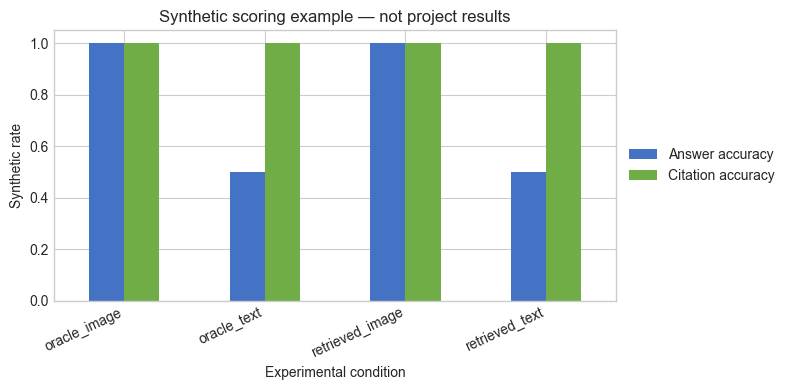

In [4]:
plot_data = synthetic_summary.set_index("condition")[["answer_accuracy", "citation_accuracy"]]
ax = plot_data.plot.bar(figsize=(8, 4), color=["#4472C4", "#70AD47"])
ax.set_title("Synthetic scoring example — not project results")
ax.set_xlabel("Experimental condition")
ax.set_ylabel("Synthetic rate")
ax.set_ylim(0, 1.05)
ax.legend(["Answer accuracy", "Citation accuracy"], loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Validation — balanced paired design

In [5]:
expected_conditions = set(conditions["condition"])
for question_id, group in synthetic_results.groupby("question_id"):
    assert set(group["condition"]) == expected_conditions, question_id
assert synthetic_results[["answer_correct", "citation_correct"]].isin([0, 1]).all().all()
assert synthetic_summary["n"].nunique() == 1

project_questions = pd.read_csv(QUESTIONS_CSV)
verified_questions = project_questions.loc[project_questions["status"] == "verified"]
real_evaluation_ready = not verified_questions.empty
print("Real evaluation ready:", real_evaluation_ready)

Real evaluation ready: False


## Interpretation

The code path can aggregate paired results, but no project conclusion is possible until verified questions and actual run records exist. Final analysis should report counts by evidence modality and question type, not only aggregate rates.

## Next step

`11_error_analysis.ipynb` defines an error taxonomy from observed parsing failures and prepares the schema for future model-run analysis.